# 02 – Utforsk MNIST

**Tid:** 90 minutter. **Mål:** forstå hvordan tall blir til bilder,
undersøke bilder og etiketter og visualisere klassefordelingen.

Vi starter med en liten matrise vi kjenner, og går så videre til MNIST:
håndskrevne sifre med 28 × 28 piksler. Vi bruker et fast tilfeldig utvalg
på 6 000 treningsbilder og 1 000 testbilder. Bildene du velger å vise,
trekkes tilfeldig og kan være forskjellige fra sidemannens.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn


## Et gråtonebilde er en matrise med tall

Et digitalt bilde består av **piksler**. I et gråtonebilde
beskriver ett tall lysstyrken til hver piksel. Tallene er ordnet i rader
og kolonner: en **matrise**, som vi kan lagre i en todimensjonal tensor.
Det er disse tallene modellen får, ikke en egen forståelse av et bilde.

Her lager vi et bilde med fire rader og fire kolonner. Med skalaen 0–1
betyr 0 svart, 1 hvitt og verdier imellom grått. `bilde[rad, kolonne]`
velger én piksel. Rad 0 ligger øverst, kolonne 0 lengst til venstre.
Et fargebilde trenger flere verdier per piksel, vanligvis rødt, grønt og
blått; MNIST har bare gråtoner.

Kjør eksemplet. Sammenlign tallmatrisen med figuren: `imshow` oversetter
hvert tall til en lysstyrke. Tallene i rutene viser koblingen direkte.


Bildet som tallmatrise:
tensor([[0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4000, 0.8000, 0.0000],
        [0.0000, 0.8000, 1.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000]])
Piksel i rad 1, kolonne 2: 0.800000011920929


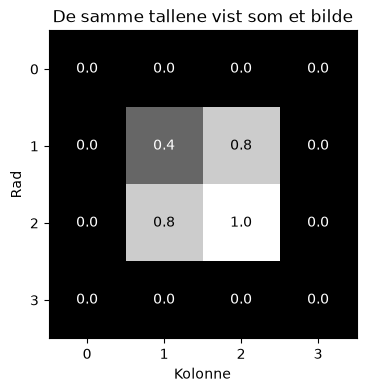

In [3]:
eksempelbilde = torch.tensor(
    [
        [0.0, 0.0, 0.0, 0.0],
        [0.0, 0.4, 0.8, 0.0],
        [0.0, 0.8, 1.0, 0.0],
        [0.0, 0.0, 0.0, 0.0],
    ]
)
print("Bildet som tallmatrise:")
print(eksempelbilde)
print("Piksel i rad 1, kolonne 2:", eksempelbilde[1, 2].item())

figur, akse = plt.subplots(figsize=(4, 4))
akse.imshow(eksempelbilde, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
for rad in range(4):
    for kolonne in range(4):
        verdi = eksempelbilde[rad, kolonne].item()
        akse.text(kolonne, rad, f"{verdi:.1f}", ha="center", va="center", color="black" if verdi > 0.5 else "white")
akse.set_xticks(range(4))
akse.set_yticks(range(4))
akse.set(xlabel="Kolonne", ylabel="Rad", title="De samme tallene vist som et bilde")
plt.show()


## Oppgave 1: Endre én piksel

Før du kjører: Hva tror du skjer hvis pikselen i rad 0, kolonne 0 endres
fra 0 til 1? Lag `endret_bilde = eksempelbilde.clone()`; `clone()` lager
en uavhengig kopi. Endre denne pikselen til 1 og vis det nye bildet med
`imshow`, gråtoner og samme faste skala (`vmin=0, vmax=1`).
Skriv også ut den nye matrisen.

<details>
<summary>Hint</summary>

`endret_bilde[0, 0] = 1.0` endrer øverste venstre piksel.
Bruk figurkoden fra eksemplet; tallene i rutene er valgfrie i din figur.

</details>


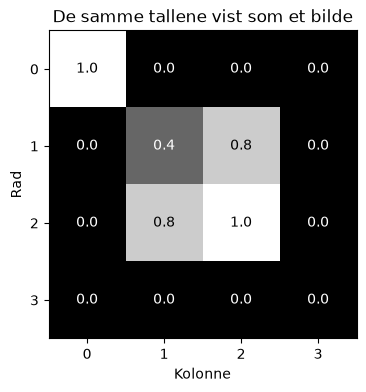

In [5]:
# Skriv din løsning her.
endret_bilde = eksempelbilde.clone()
endret_bilde[0, 0] = 1

figur, akse = plt.subplots(figsize=(4, 4))
akse.imshow(endret_bilde, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
for rad in range(4):
    for kolonne in range(4):
        verdi = endret_bilde[rad, kolonne].item()
        akse.text(kolonne, rad, f"{verdi:.1f}", ha="center", va="center", color="black" if verdi > 0.5 else "white")
akse.set_xticks(range(4))
akse.set_yticks(range(4))
akse.set(xlabel="Kolonne", ylabel="Rad", title="De samme tallene vist som et bilde")
plt.show()

**Kontroll:** Kjør cellen når du har endret bildet.


In [6]:
assert endret_bilde.shape == eksempelbilde.shape
assert endret_bilde[0, 0].item() == 1.0
assert eksempelbilde[0, 0].item() == 0.0
assert (endret_bilde != eksempelbilde).sum().item() == 1


### Sjekk forståelsen

Skriv hva du forventet før kjøring, og hva du observerte.
Hvor i bildet skjedde endringen, og hvorfor akkurat der?
Har matrisen og bildet forskjellig informasjon, eller er de to visninger
av de samme verdiene? Forklar også hvorfor lysstyrke 0.8 ikke betyr
at modellen er 80 % sikker på et siffer.

Skriv svaret ditt i Markdown-cellen under.


**Mitt svar:**

...


## Ferdig kode: last ned og hent datasettet

Nå går vi fra den lille matrisen til håndskrevne sifre. Første gang
lastes MNIST ned til prosjektets `data/`-mappe. Senere brukes de samme
lokale filene. Hele MNIST lastes ned, men vi bruker bare delutvalget.

Et **datasett** lar oss hente ett par `(bilde, etikett)` med en indeks,
omtrent som fra en liste. `bilde` inneholder pikselverdiene, og `etikett`
forteller hvilket siffer bildet forestiller. Vi undersøker ett bilde
om gangen før vi prøver å lære fra dem.


In [1]:
from pytorch_101.utils import download_mnist

treningsdata, testdata = download_mnist()
print(f"Treningsbilder: {len(treningsdata)}, testbilder: {len(testdata)}")


Treningsbilder: 6000, testbilder: 1000


## Samme idé, flere piksler

Rå MNIST-bilder er matriser med 28 rader og 28 kolonner. Hvert tall er
en pikselverdi fra 0 til 255. For å se et siffer velger vi gråtoner for
disse verdiene; akkurat som i 4 × 4-eksemplet, bare med flere ruter.

Datahjelperen bruker `ToTensor`, som skalerer tallene til 0–1 og legger
til en **kanalakse**. Derfor har bildet formen `[1, 28, 28]`:
én gråtonekanal, 28 rader og 28 kolonner. Etiketten lagres separat.
`bilde[0, rad, kolonne]` henter én piksel fra denne ene kanalen.

Cellen under henter råbildet og den skalerte versjonen av samme bilde.
Legg merke til at en liten utskjæring av bildet også bare er tall.


In [ ]:
bilde, etikett = treningsdata[0]
opprinnelig_indeks = treningsdata.indices[0]
raabilde = treningsdata.dataset.data[opprinnelig_indeks]
print("Råbilde:", raabilde.shape, raabilde.dtype, raabilde.min().item(), raabilde.max().item())
print("Modellens bilde:", bilde.shape, bilde.dtype, bilde.min().item(), bilde.max().item())
print("Etikett:", etikett)

print("Et utsnitt av pikselmatrisen:")
print(bilde[0, 10:16, 10:16])


## Oppgave 2: Vis et MNIST-bilde

Trekk en tilfeldig indeks i `treningsdata`, og hent bilde og etikett derfra.
Kall dem `mitt_bilde` og
`min_etikett`. Vis bildet i gråtoner med etiketten i tittelen, uten akser.
Skriv også ut form, datatype og minste og største pikselverdi.

<details>
<summary>Hint</summary>

`torch.randint(len(treningsdata), ()).item()` trekker en indeks.
`mitt_bilde.squeeze(0)` endrer formen fra `[1, 28, 28]` til `[28, 28]`.

</details>


In [ ]:
# Skriv din løsning her.


**Kontroll:** Kjør denne cellen når du har løst oppgaven. En feilmelding betyr at du må undersøke løsningen.


In [ ]:
assert mitt_bilde.shape == (1, 28, 28)
assert 0 <= min_etikett <= 9
assert 0 <= mitt_bilde.min() <= mitt_bilde.max() <= 1


### Sjekk forståelsen

Hva betyr dimensjonene i formen til `mitt_bilde`? Hvorfor fjerner vi
første dimensjon ved visning? Hva betyr svart og hvitt med denne fargeskalaen?

Skriv svaret ditt i Markdown-cellen under. Bruk egne resultater der det er relevant.


**Mitt svar:**

...


## Eksempel: flere bilder i samme figur

`subplots` lager flere akser. `ravel()` gir oss en flat liste av aksene, slik
at vi kan bruke en vanlig løkke. Hver akse får sitt eget bilde og sin egen tittel.


In [ ]:
eksempelbilder = [eksempelbilde, 1 - eksempelbilde, eksempelbilde.T, torch.zeros_like(eksempelbilde)]
figur, akser = plt.subplots(2, 2, figsize=(5, 5))
for indeks, akse in enumerate(akser.ravel()):
    akse.imshow(eksempelbilder[indeks], cmap="gray", vmin=0, vmax=1)
    akse.set_title(f"Eksempel {indeks}")
    akse.axis("off")
figur.tight_layout()
plt.show()


## Oppgave 3: Lag et bilderutenett

Lag en figur med 3 × 3 akser. Trekk ni forskjellige treningsbilder og vis dem med riktig
etikett over hvert bilde. Bruk samme gråtoneskala i alle rutene.

<details>
<summary>Hint</summary>

Bruk `torch.randperm(len(treningsdata))[:9].tolist()` for ni ulike indekser.
Kombiner dem med aksene ved hjelp av `zip(akser.ravel(), bildeindekser)`.

</details>


In [ ]:
# Skriv din løsning her.


## Eksempel: tell kategorier og tegn et stolpediagram

Klasseetiketter er kategorier. Derfor bruker vi ett stolpediagram med én stolpe
per kategori. Vi starter med en liten liste frukter og en vanlig Python-løkke.


In [ ]:
frukter = ["eple", "pære", "eple", "banan", "pære", "eple"]
kategorier = ["eple", "pære", "banan"]
antall_frukt = [frukter.count(kategori) for kategori in kategorier]
figur, akse = plt.subplots()
akse.bar(kategorier, antall_frukt)
akse.set(xlabel="Frukt", ylabel="Antall", title="Fordeling av frukter")
plt.show()


## Oppgave 4: Undersøk klassefordelingen

Tell hvor mange bilder det er av hvert siffer i **treningsutvalget**.
Lag listen `klasseantall` med ti tall, der indeks 0 er antall nuller.
Lag et stolpediagram med siffer på x-aksen og antall bilder på y-aksen.
Vis alle sifrene 0–9 langs x-aksen. Skriv også ut antallene.

<details>
<summary>Hint</summary>

Start med `klasseantall = [0] * 10`. For hvert `bilde, etikett` i datasettet:
øk `klasseantall[etikett]` med 1. Bruk `range(10)` som stolpenes posisjoner.

</details>


In [ ]:
# Skriv din løsning her.


**Kontroll:** Kjør denne cellen når du har løst oppgaven. En feilmelding betyr at du må undersøke løsningen.


In [ ]:
assert len(klasseantall) == 10
assert sum(klasseantall) == len(treningsdata)
assert all(antall > 0 for antall in klasseantall)


### Sjekk forståelsen

Hvilket siffer forekommer oftest og sjeldnest? Oppgi begge antallene fra din kjøring.
Er fordelingen omtrent jevn? Hvorfor kan en svært skjev fordeling være et problem
ved trening og når vi rapporterer samlet nøyaktighet?

Skriv svaret ditt i Markdown-cellen under. Bruk egne resultater der det er relevant.


**Mitt svar:**

...


**Neste steg:** Vi skal bruke pikselverdiene til å beregne skårer for de ti sifrene.
